In [21]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv(r'C:\Users\Asus\OneDrive\Documents\zohra shaikh\pandas\Data Launch Analysis\mission_launches.csv')

In [5]:
df = df.drop(columns=['Unnamed: 0.1' , 'Unnamed: 0'], errors='ignore')

In [6]:
df.head()

,Organisation,Location,Date,Detail,Rocket_Status,Price,Mission_Status
0,SpaceX,"LC-39A, Kennedy Space Center, Florida, USA","Fri Aug 07, 2020 05:12 UTC",Falcon 9 Block 5 | Starlink V1 L9 & BlackSky,StatusActive,50.0,Success
1,CASC,"Site 9401 (SLS-2), Jiuquan Satellite Launch Ce...","Thu Aug 06, 2020 04:01 UTC",Long March 2D | Gaofen-9 04 & Q-SAT,StatusActive,29.75,Success
2,SpaceX,"Pad A, Boca Chica, Texas, USA","Tue Aug 04, 2020 23:57 UTC",Starship Prototype | 150 Meter Hop,StatusActive,NaN,Success
3,Roscosmos,"Site 200/39, Baikonur Cosmodrome, Kazakhstan","Thu Jul 30, 2020 21:25 UTC",Proton-M/Briz-M | Ekspress-80 & Ekspress-103,StatusActive,65.0,Success
4,ULA,"SLC-41, Cape Canaveral AFS, Florida, USA","Thu Jul 30, 2020 11:50 UTC",Atlas V 541 | Perseverance,StatusActive,145.0,Success


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4324 entries, 0 to 4323
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Organisation    4324 non-null   str  
 1   Location        4324 non-null   str  
 2   Date            4324 non-null   str  
 3   Detail          4324 non-null   str  
 4   Rocket_Status   4324 non-null   str  
 5   Price           964 non-null    str  
 6   Mission_Status  4324 non-null   str  
dtypes: str(7)
memory usage: 763.0 KB


In [11]:
pd.set_option('display.max_rows', None)

In [12]:
# Converting Price to float and Date to datetime
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

In [13]:
# Which organisation conducted the most launches
df['Organisation'].value_counts()

Organisation
RVSN USSR           1777
Arianespace          279
CASC                 251
General Dynamics     251
NASA                 203
VKS RF               201
US Air Force         161
ULA                  140
Boeing               136
Martin Marietta      114
SpaceX               100
MHI                   84
Northrop              83
Lockheed              79
ISRO                  76
Roscosmos             55
ILS                   46
Sea Launch            36
ISAS                  30
Kosmotras             22
US Navy               17
Rocket Lab            13
ISA                   13
Eurockot              13
ESA                   13
Blue Origin           12
IAI                   11
ExPace                10
ASI                    9
CNES                   8
AMBA                   8
JAXA                   7
Land Launch            7
MITT                   7
CASIC                  5
KCST                   5
UT                     5
Exos                   4
CECLES                 4
Arm??e de l'

### Interpretation

RVSN USSR recorded the highest number of launches in this dataset. This shows that it contributed a large share of the recorded launch activity. However, having more launches does not automatically mean having a higher success rate.

In [14]:
# How many missions were successful vs unsuccessful?
df['Mission_Status'].value_counts()

Mission_Status
Success              3879
Failure               339
Partial Failure       102
Prelaunch Failure       4
Name: count, dtype: int64

### Interpretation

Most recorded missions were successful. However, some missions experienced complete, partial, or prelaunch failures, so launch history includes both successes and setbacks.

In [15]:
df['Year'] = df['Date'].dt.year.astype('Int64')

# How did the number of launches changed over years
launch_yearwise = df['Year'].value_counts().sort_index()
launch_yearwise

Year
1957      3
1958     22
1959     20
1960     38
1961     52
1962     81
1963     38
1964     56
1965     86
1966     98
1967    102
1968    100
1969    101
1970    106
1971    116
1972     96
1973     99
1974     97
1975    112
1976    109
1977    109
1978     93
1979     46
1980     52
1981     66
1982     66
1983     64
1984     67
1985     71
1986     61
1987     54
1988     56
1989     50
1990     76
1991     57
1992     62
1993     61
1994     62
1995     60
1996     60
1997     69
1998     67
1999     53
2000     57
2001     42
2002     46
2003     49
2004     39
2005     37
2006     49
2007     49
2008     47
2009     49
2010     36
2011     41
2012     34
2013     46
2014     52
2015     46
2016     88
2017     90
2018    117
2019    107
2020     63
Name: count, dtype: Int64

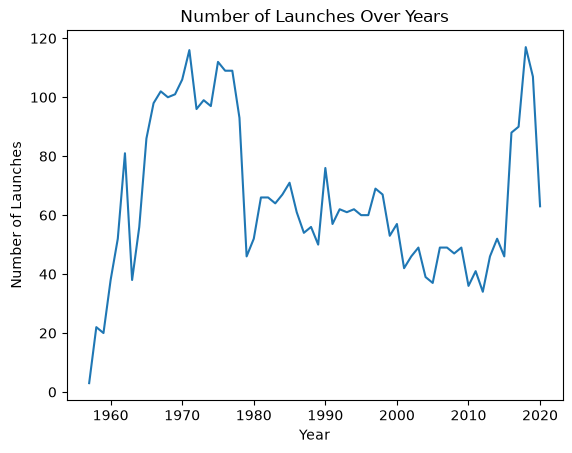

In [24]:
line_plot = launch_yearwise.plot(kind='line', title='Number of Launches Over Years', xlabel='Year', ylabel='Number of Launches')

### Interpretation

The number of space mission launches generally increased over time, although there were fluctuations between years. Launch activity reached 117 launches in 2018, the highest annual total in the dataset. The number decreased to 107 in 2019 and 63 in 2020. However, the 2020 data ends in August, so it represents an incomplete year and should not be directly compared with full years.

In [16]:
# Which organisation have the highest number of succesful missions
successful_launches = df.loc[df['Mission_Status'] == 'Success'].value_counts('Organisation')
successful_launches

Organisation
RVSN USSR           1614
Arianespace          269
CASC                 231
General Dynamics     203
VKS RF               188
NASA                 186
ULA                  139
Boeing               131
US Air Force         129
Martin Marietta      100
SpaceX                94
MHI                   80
Northrop              74
Lockheed              74
ISRO                  63
Roscosmos             51
ILS                   45
Sea Launch            33
ISAS                  26
Kosmotras             21
Blue Origin           12
Eurockot              12
Rocket Lab            11
IAI                    9
ExPace                 9
ESA                    9
ASI                    9
JAXA                   6
Land Launch            6
MITT                   6
CNES                   6
ISA                    4
AMBA                   4
CASIC                  3
Arm??e de l'Air        3
KCST                   2
SRC                    2
Yuzhmash               2
OKB-586                2
US Navy     

<Axes: title={'center': 'Top 10 Organisations with Successful Launches'}, xlabel='Organisation', ylabel='Number of Successful Launches'>

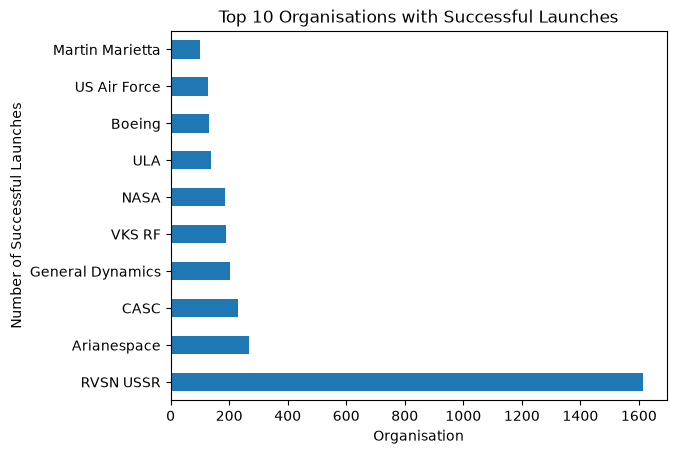

In [86]:
# Plotting the top 10 organisations with the most successful launches
successful_launches.head(10).sort_values(ascending=False).plot(
    kind='barh', 
    title='Top 10 Organisations with Successful Launches', 
    xlabel='Organisation', 
    ylabel='Number of Successful Launches'
)

### Interpretation

RVSN USSR recorded the highest absolute number of successful missions in the dataset. This indicates that it contributed more successful missions than any other organisation in the recorded data. However, the total number of successful missions does not necessarily indicate the highest success rate, so success rates should also be compared.

In [17]:
# Which launches location are used most?
launches_location = df['Location'].value_counts()
launches_location

Location
Site 31/6, Baikonur Cosmodrome, Kazakhstan                                                 235
Site 132/1, Plesetsk Cosmodrome, Russia                                                    216
Site 43/4, Plesetsk Cosmodrome, Russia                                                     202
Site 41/1, Plesetsk Cosmodrome, Russia                                                     198
Site 1/5, Baikonur Cosmodrome, Kazakhstan                                                  193
Site 132/2, Plesetsk Cosmodrome, Russia                                                    174
Site 133/3, Plesetsk Cosmodrome, Russia                                                    158
Site 43/3, Plesetsk Cosmodrome, Russia                                                     138
LC-39A, Kennedy Space Center, Florida, USA                                                 120
ELA-2, Guiana Space Centre, French Guiana, France                                          118
SLC-40, Cape Canaveral AFS, Florida, USA 

### Interpretation

Site 31/6, Baikonur Cosmodrome, Kazakhstan, was the most frequently used launch location, recording 235 launches. This suggests that the location played a significant role in the space mission launch activity represented in the dataset. The result refers to a specific launch site, not to the total number of launches conducted by Kazakhstan.

In [37]:
# Calculate overall average launch cost
avg_cost = df['Price'].mean()
print("Average overall cost: ", avg_cost)

# Calculate average cost per organisation and sort from highest to lowest
avg_org_cost = df.groupby('Organisation')['Price'].mean()
highest_avg_cost = avg_org_cost.dropna().sort_values(ascending=False)
highest_avg_cost

Average overall cost:  129.79523709167546


Organisation
NASA               450.000000
Boeing             177.285714
Arianespace        170.260417
ULA                151.000000
ILS                101.538462
MHI                 95.472973
Martin Marietta     80.155556
US Air Force        59.650769
JAXA                56.000000
SpaceX              54.989899
Roscosmos           51.630435
Northrop            47.349398
VKS RF              46.936364
Eurockot            41.800000
CASC                40.128228
ESA                 37.000000
Lockheed            35.000000
ISRO                32.492537
Kosmotras           29.000000
ExPace              28.300000
EER                 20.000000
Sandia              15.000000
Virgin Orbit        12.000000
Rocket Lab           7.500000
Name: Price, dtype: float64

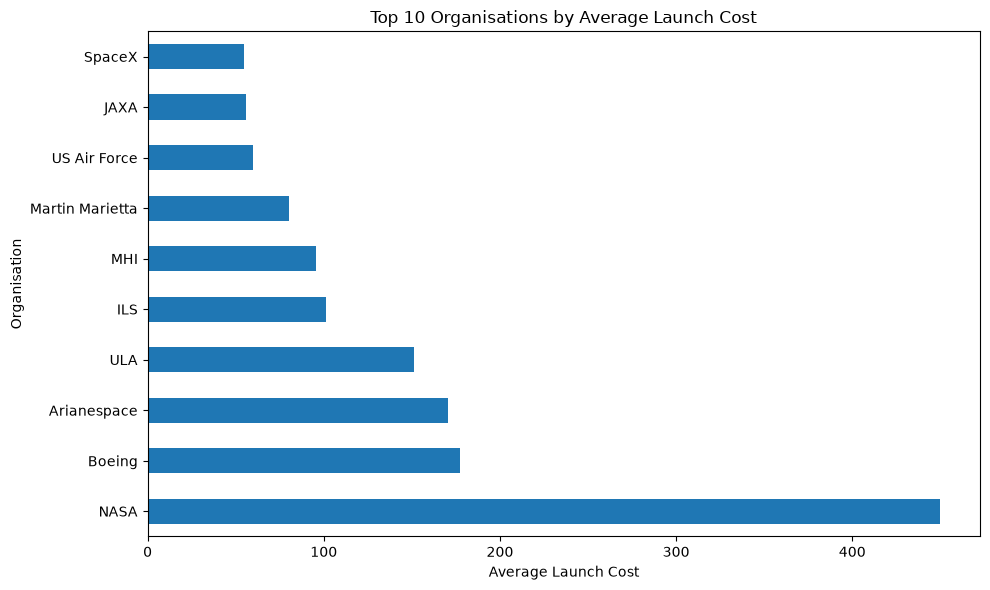

In [ ]:
# Plotting the top 10 organisations by average launch cost
highest_avg_cost.head(10).sort_values(ascending=False).plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Top 10 Organisations by Average Launch Cost')
plt.xlabel('Average Launch Cost')
plt.ylabel('Organisation')
plt.tight_layout()
plt.show()

### Interpretation

The average recorded launch cost across the dataset was approximately 129.80. NASA had the highest average recorded launch cost at 450.00, followed by Boeing at 177.29 and Arianespace at 170.26. Rocket Lab had the lowest average among the listed organisations at 7.50. However, price information is available for only a portion of the missions, and the dataset's price units need to be confirmed. Therefore, these averages should be interpreted with caution.

In [85]:
# Does launch cost appear to differ between successful and failed missions
status_total = df[df['Mission_Status'].isin(['Success', 'Failure'])].groupby('Mission_Status')['Price'].mean()
status_diff_cost = df.groupby(['Organisation', 'Mission_Status'])['Price'].mean().unstack()

display(status_total)
display(status_diff_cost)

Mission_Status
Failure     67.359444
Success    133.316451
Name: Price, dtype: float64

Mission_Status,Failure,Partial Failure,Prelaunch Failure,Success
Organisation,,,,
AEB,NaN,NaN,NaN,NaN
AMBA,NaN,NaN,NaN,NaN
ASI,NaN,NaN,NaN,NaN
Arianespace,118.500000,200.000000,NaN,171.053763
Arm??e de l'Air,NaN,NaN,NaN,NaN
Blue Origin,NaN,NaN,NaN,NaN
Boeing,NaN,350.000000,NaN,148.500000
CASC,52.836667,42.866667,NaN,39.823355
CASIC,NaN,NaN,NaN,NaN


### Interpretation

This analysis compares the average recorded launch costs of successful and failed missions. The calculated averages can help identify whether launch costs differ between these two mission outcomes. However, the conclusion should be based on the actual averages produced by the analysis. A difference in average cost does not establish that launch cost causes mission success or failure, and missing price values may affect the comparison.

In [84]:
df['is_success'] = df['Mission_Status'] == 'Success'

In [44]:
# Which organisations have the best success rate
org_stats = df.groupby('Organisation').agg(
    total_launches=('Mission_Status', 'count'),
    successful_launches=('is_success','mean')
)

org_stats['success_rate'] = org_stats['successful_launches'] * 100

org_stats = org_stats[org_stats['total_launches'] >= 10]

org_stats = org_stats.sort_values(by='success_rate', ascending=False)

org_stats


,total_launches,successful_launches,success_rate
Organisation,,,
Blue Origin,12,1.000000,100.000000
ULA,140,0.992857,99.285714
ILS,46,0.978261,97.826087
Arianespace,279,0.964158,96.415771
Boeing,136,0.963235,96.323529
Kosmotras,22,0.954545,95.454545
MHI,84,0.952381,95.238095
SpaceX,100,0.940000,94.000000
Lockheed,79,0.936709,93.670886


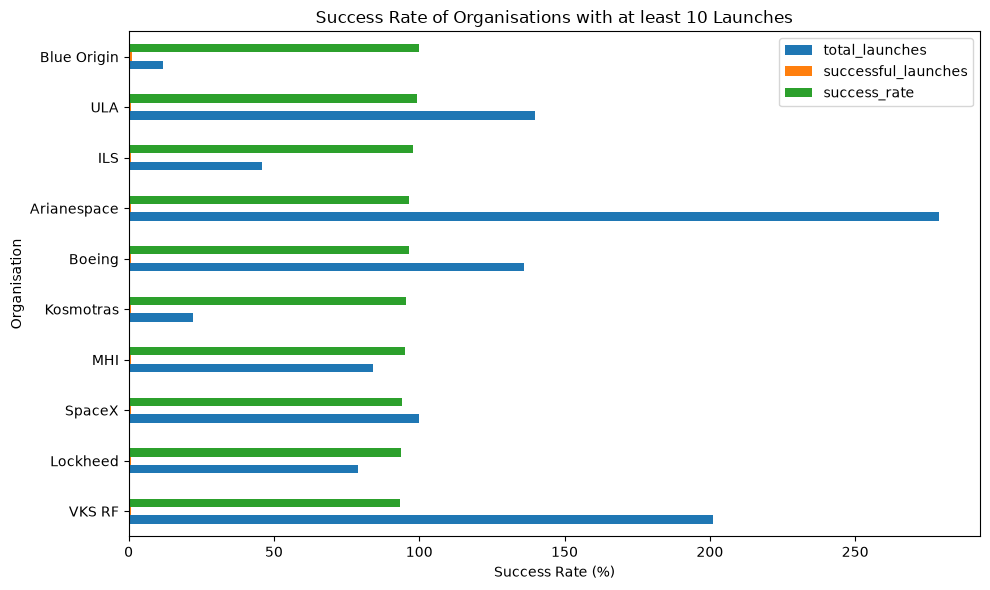

In [ ]:
# Plotting the success rate of organisations with at least 10 launches
org_stats.head(10).sort_values(by='success_rate', ascending=True).plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Success Rate of Organisations with at least 10 Launches')
plt.xlabel('Success Rate (%)')
plt.ylabel('Organisation')
plt.tight_layout()
plt.show()

### Interpretation

This analysis compares the success rates of organisations with at least 10 recorded launches. A higher success rate means that a larger proportion of an organisation's recorded missions were successful. Considering the total number of launches alongside the success rate helps provide a more balanced comparison of organisational performance.